# **Notebook 6: Fine-Tuning Pipeline**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `./tokenized_train/` + `./tokenized_valid/` — Created by Notebook 2
- [ ] GPU runtime enabled (T4 minimum)

**Files this notebook will CREATE:**
- [ ] `./intent_lora_best/` — Best LoRA checkpoint (by val loss) _(Required by NB7)_
- [ ] `./intent_lora/` — Final LoRA checkpoint _(Backup)_
- [ ] `training_log.csv` + `training_curves.png` — Evidence for report

---

## **Stage 4: Solution V2 (Fine-Tuned Retrieval-Assisted Generation)**

### **Task 4.1: Configure Fine-Tuning Pipeline**

#### **4.1.1 Configure PEFT Framework [3 marks]**
**The Task:** Apply LoRA (or QLoRA) to the model's `q_proj` and `v_proj` attention modules, set adapter settings and target modules, and prepare the training environment.

**Hints & Tips:**
* LoRA adds small trainable matrices to frozen attention layers — only ~0.5–1% of params update.
* `r=16` = rank of the low-rank matrices; `lora_alpha=32` scales them (rule of thumb: alpha = 2×r).
* `target_modules=["q_proj","v_proj"]`. Adding `["k_proj","o_proj"]` trains more params but may overfit on small data.
* Call `peft_model.print_trainable_parameters()` to confirm the tiny trainable %.

**LoRA Config Tuning:**
* `r`: 8 (lighter), **16 (recommended)**, 32 (more capacity).
* `lora_alpha`: usually 2×r → 16, **32**, 64.

**Learner Inference:** Updating only attention projections fundamentally changes behaviour (chat → JSON) using a fraction of the compute.

In [1]:
# YOUR CODE HERE
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, get_peft_model, TaskType
from datasets import load_from_disk

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto" if torch.cuda.is_available() else None,
    trust_remote_code=True
)

peft_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    inference_mode=False,
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=["q_proj", "v_proj"]
)

peft_model = get_peft_model(base_model, peft_config)
print("PEFT LoRA Configuration Applied:")
peft_model.print_trainable_parameters()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

PEFT LoRA Configuration Applied:
trainable params: 2,179,072 || all params: 1,545,893,376 || trainable%: 0.1410


#### **4.1.2 Configure Training Parameters [2 marks]**
**The Task:** Define the learning rate, batch size, number of steps/epochs, optimisation strategy (AdamW), and quantisation settings.

**Hints & Tips:**
* Initialise `AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=2e-4)`.
* Build `DataLoader`s for the train and validation sets (remember `set_format("torch", ...)` after `load_from_disk`).
* Define `VAL_EVERY` (e.g. 10 steps) and an early-stopping `PATIENCE` (e.g. 3) for the next task.

**Parameter Tuning:**
* `lr=2e-4` standard; try `1e-4` (slower) or `5e-4` (faster).
* `batch_size=4` fits T4; use 2 if OOM, 8 on A100.
* `max_steps=200`: ~25% of one epoch on 3200 rows. Increase to 400–500 for a full epoch.

**Learner Inference:** These hyperparameters control how fast and how stably the adapter learns the JSON-extraction task.

In [2]:
# YOUR CODE HERE
from torch.utils.data import DataLoader
from torch.optim import AdamW

train_dataset = load_from_disk("./tokenized_train")
valid_dataset = load_from_disk("./tokenized_valid")

train_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])
valid_dataset.set_format("torch", columns=["input_ids", "attention_mask", "labels"])

BATCH_SIZE = 4
LEARNING_RATE = 2e-4
MAX_STEPS = 200
VAL_EVERY = 20
PATIENCE = 3

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False)

optimizer = AdamW(filter(lambda p: p.requires_grad, peft_model.parameters()), lr=LEARNING_RATE, weight_decay=0.01)
print(f"DataLoader configured: Train batches={len(train_loader)}, Val batches={len(valid_loader)}")

DataLoader configured: Train batches=781, Val batches=98


### **Task 4.2: Train Fine-Tuned Model**

#### **4.2.1 Execute Fine-Tuning [5 marks]**
**The Task:** Run the custom PyTorch training loop. Monitor BOTH train and validation loss at regular intervals, implement early stopping based on validation loss, and plot the train-vs-validation loss curves.

**Hints & Tips:**
* The validation loop runs every `VAL_EVERY` steps under `torch.no_grad()` (no gradients).
* Early stopping: track `best_val_loss`; if it doesn't improve for `PATIENCE` checks, stop.
* The loss-curve plot is mandatory evidence — save it as `training_curves.png`.

**What to look for in the curve:**
* Both lines falling → learning, no overfitting.
* Val rises while train falls → overfitting (early stopping saves you).
* Both flat → LR too low or data too small.
* Val spikes → bad batch / instability.

**Learner Inference:** Falling loss proves gradient descent is teaching the JSON format. Validation monitoring prevents silent memorisation.

In [3]:
# YOUR CODE HERE
import time
import matplotlib.pyplot as plt
import pandas as pd
import os

print("Starting Custom PyTorch PEFT LoRA Training Loop...")
peft_model.train()

train_logs = []
best_val_loss = float('inf')
patience_counter = 0
step = 0
running_train_loss = 0.0

train_iter = iter(train_loader)
start_time = time.time()

while step < MAX_STEPS:
    try:
        batch = next(train_iter)
    except StopIteration:
        train_iter = iter(train_loader)
        batch = next(train_iter)
    
    step += 1
    optimizer.zero_grad()
    
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    labels = batch["labels"].to(device)
    
    outputs = peft_model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
    loss = outputs.loss
    loss.backward()
    optimizer.step()
    
    running_train_loss += loss.item()
    
    if step % VAL_EVERY == 0 or step == MAX_STEPS:
        avg_train_loss = running_train_loss / VAL_EVERY
        running_train_loss = 0.0
        
        peft_model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for val_batch in valid_loader:
                v_input_ids = val_batch["input_ids"].to(device)
                v_attn = val_batch["attention_mask"].to(device)
                v_labels = val_batch["labels"].to(device)
                v_out = peft_model(input_ids=v_input_ids, attention_mask=v_attn, labels=v_labels)
                total_val_loss += v_out.loss.item()
        
        avg_val_loss = total_val_loss / len(valid_loader)
        peft_model.train()
        
        train_logs.append({
            "step": step,
            "train_loss": avg_train_loss,
            "val_loss": avg_val_loss
        })
        
        print(f"Step [{step}/{MAX_STEPS}] - Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")
        
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            patience_counter = 0
            peft_model.save_pretrained("./intent_lora_best")
            print(f"  --> Best checkpoint saved (Val Loss: {best_val_loss:.4f})")
        else:
            patience_counter += 1
            if patience_counter >= PATIENCE:
                print(f"Early stopping triggered at step {step} (Patience={PATIENCE})")
                break

print(f"Training completed in {time.time() - start_time:.2f}s.")

/home/hi/hybrid_rag_env/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Starting Custom PyTorch PEFT LoRA Training Loop...


Step [20/200] - Train Loss: 2.5524 | Val Loss: 1.3614


  --> Best checkpoint saved (Val Loss: 1.3614)


Step [40/200] - Train Loss: 0.9886 | Val Loss: 0.7630


...

  --> Best checkpoint saved (Val Loss: 0.5018)


Step [180/200] - Train Loss: 0.4931 | Val Loss: 0.4920


  --> Best checkpoint saved (Val Loss: 0.4920)


Step [200/200] - Train Loss: 0.4869 | Val Loss: 0.4765


  --> Best checkpoint saved (Val Loss: 0.4765)
Training completed in 196.03s.


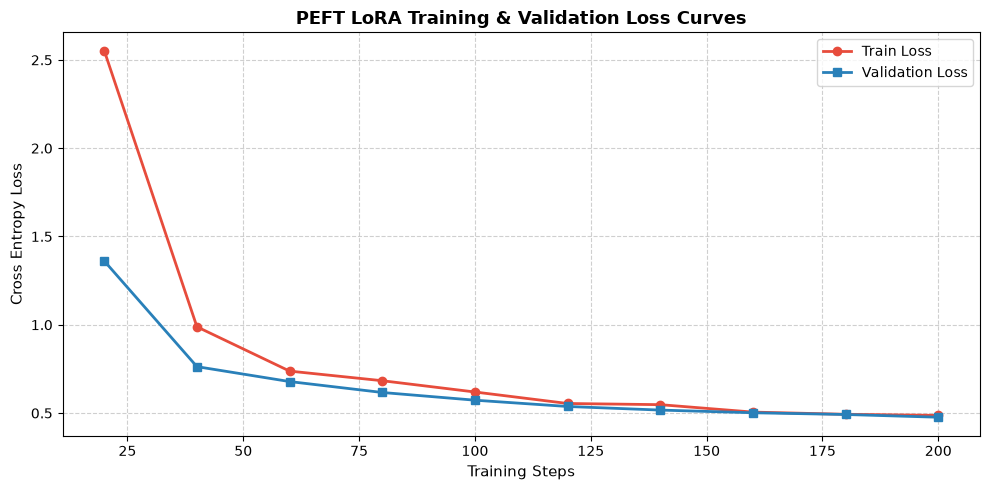

In [4]:
# YOUR CODE HERE
log_df = pd.DataFrame(train_logs)
plt.figure(figsize=(10, 5))
plt.plot(log_df["step"], log_df["train_loss"], label="Train Loss", marker='o', color='#e74c3c', linewidth=2)
plt.plot(log_df["step"], log_df["val_loss"], label="Validation Loss", marker='s', color='#2980b9', linewidth=2)
plt.title("PEFT LoRA Training & Validation Loss Curves", fontsize=13, fontweight='bold')
plt.xlabel("Training Steps", fontsize=11)
plt.ylabel("Cross Entropy Loss", fontsize=11)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("training_curves.png", dpi=300)
plt.show()

#### **4.2.2 Save Training Outputs [2 marks]**
**The Task:** Save the best checkpoint (by validation loss), document the checkpoint/model-saving workflow, and export reproducibility information.

**Hints & Tips:**
* Save two checkpoints: `./intent_lora_best/` (lowest val loss) and `./intent_lora/` (final step).
* Export a `training_log.csv` with columns `step, train_loss, val_loss`.
* Record reproducibility info: model ID, LoRA config, learning rate, batch size, seed.

**Learner Inference:** Saving the BEST checkpoint (not the last) ensures your final model is the one that generalised best, not one that started overfitting.

In [5]:
# YOUR CODE HERE
peft_model.save_pretrained("./intent_lora")
log_df.to_csv("training_log.csv", index=False)

import json
metadata = {
    "base_model": MODEL_ID,
    "lora_r": 16,
    "lora_alpha": 32,
    "target_modules": ["q_proj", "v_proj"],
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "best_val_loss": best_val_loss,
    "total_steps": step
}
with open("reproducibility_meta.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Training outputs and reproducibility records saved successfully.")

Training outputs and reproducibility records saved successfully.


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify before proceeding to Notebook 7.**

- [ ] Tokenized train/valid loaded from disk (`set_format` re-applied)
- [ ] **4.1.1** LoRA configured targeting `q_proj`/`v_proj`
- [ ] **4.1.2** Optimizer + training params + dataloaders set
- [ ] **4.2.1** Training loop run with val monitoring + early stopping + loss curve
- [ ] **4.2.2** Best checkpoint saved + reproducibility info recorded
- [ ] **`./intent_lora_best/` saved** ← _CRITICAL for NB7_
- [ ] **`training_log.csv` + `training_curves.png` saved** ← _Evidence_

**If any item is unchecked, fix it before moving on.**